In [123]:

# PHASE 2 - NETTOYAGE ET VALIDATION STRUCTURELLE

# Importer les bibliothèques
import pandas as pd
import sys

# Charger les données en conservant les valeurs "NULL" et "N/A"
df = pd.read_csv(
    "../starter-kit/data/numeros_tva.csv",
    keep_default_na=False
)

# Importer le module de validation fourni par le formateur
sys.path.append("../starter-kit")
from validation_structure import normaliser, valider, PAYS_COUVERTS

# Tester les fonctions de normalisation et de validation
print(normaliser(" fr 552032534 "))
print(valider("FR27552032534"))
print(valider("FR99552032534"))

# Valider les 10 000 numéros de TVA
df["resultat_validation"] = df["numero_tva"].apply(valider)

# Identifier les préfixes des numéros normalisés
df["prefixe_normalise"] = (
    df["numero_tva"].apply(normaliser).str.slice(0, 2)
)

# Identifier les numéros sans préfixe pays
masque = df["prefixe_normalise"].str.isdigit()

# Reconstituer les numéros à partir du pays déclaré
df.loc[masque, "numero_reconstitue"] = (
    df.loc[masque, "pays_declare"]
    + df.loc[masque, "numero_tva"].apply(normaliser)
)

# Vérifier la structure des numéros reconstitués
df.loc[masque, "validation_reconstitue"] = (
    df.loc[masque, "numero_reconstitue"].apply(valider)
)

# Créer la colonne des numéros définitifs
df["numero_final"] = df["numero_tva"].apply(normaliser)

# Remplacer les numéros sans préfixe par leur version reconstituée
df.loc[masque, "numero_final"] = df.loc[
    masque, "numero_reconstitue"
]

# Sélectionner les numéros structurellement valides
valides = (
    (df["resultat_validation"] == (True, "ok"))
    | (df["validation_reconstitue"] == (True, "ok"))
)

# Éliminer les doublons
numeros_uniques = (
    df.loc[valides, "numero_final"].drop_duplicates()
)

# Afficher les résultats du nettoyage
print("Nombre de lignes initiales :", len(df))
print("Numéros sans préfixe :", masque.sum())
print("Numéros structurellement valides :", valides.sum())
print("Doublons :", df.loc[valides, "numero_final"].duplicated().sum())
print("Numéros uniques :", len(numeros_uniques))

# Répartition des numéros uniques par pays
print(numeros_uniques.str.slice(0, 2).value_counts())


FR552032534
(True, 'ok')
(False, 'cle_invalide')
Nombre de lignes initiales : 10000
Numéros sans préfixe : 532
Numéros structurellement valides : 6615
Doublons : 313
Numéros uniques : 6302
numero_final
PL    659
LU    652
PT    650
BE    644
FR    643
SE    630
DK    620
NL    619
IT    604
FI    581
Name: count, dtype: int64


## Bilan du nettoyage et décisions

Sur les 10 000 numéros de TVA analysés, 6 083 étaient initialement structurellement valides.

Nous avons identifié 532 numéros sans préfixe pays. Grâce au pays déclaré dans le CRM, nous avons pu reconstituer ces numéros. Ils passent désormais le contrôle structurel, mais leur existence réelle reste à vérifier.

Nous n'avons pas corrigé les 2 605 numéros présentant une clé invalide, car nous ne disposons pas d'informations suffisamment fiables pour déterminer leur valeur correcte.

Après correction, nous obtenons 6 615 numéros structurellement valides. Nous avons ensuite identifié 313 doublons en comparant les numéros normalisés et reconstitués.

**Résultat : 6 302 numéros uniques candidats à une vérification VIES, soit 3 698 appels potentiellement évités.**

**Limites :** la reconstitution repose sur le pays déclaré dans le CRM, qui peut être erroné. De plus, un numéro structurellement valide n'est pas nécessairement actif ou enregistré dans VIES.

In [124]:

# ============================================================
# PHASE 4 - ANALYSE ET RAPPORT DE RECONCILIATION
# ============================================================

import pandas as pd
from pathlib import Path

# Localiser le fichier produit par le script de collecte
chemin_vies = Path("../api/resultats_vies.csv")

# Charger les tentatives VIES
df_vies = pd.read_csv(chemin_vies, dtype=str)

print("=== RESULTATS DE LA COLLECTE VIES ===")

print("Nombre total de tentatives :", len(df_vies))

print(
    "Nombre de numéros différents :",
    df_vies["numero_final"].nunique()
)

print("\nRéponses retournées par VIES :")
print(df_vies["erreur_vies"].value_counts(dropna=False))

display(df_vies.head(10))


=== RESULTATS DE LA COLLECTE VIES ===
Nombre total de tentatives : 5
Nombre de numéros différents : 3

Réponses retournées par VIES :
erreur_vies
MS_MAX_CONCURRENT_REQ    4
INVALID                  1
Name: count, dtype: int64


,numero_final,pays,code_http,erreur_vies,valide_vies,duree,date,erreur_technique,reponse_complete
0,FR36440645206,FR,200,INVALID,False,7.975392299995292,2026-11-18T15:48:41,NaN,"{""isValid"": false, ""requestDate"": ""2026-11-18T..."
1,FR62581261976,FR,200,MS_MAX_CONCURRENT_REQ,NaN,0.09737740000127815,2026-11-18T15:48:43,Réponse VIES non concluante : MS_MAX_CONCURREN...,"{""isValid"": false, ""requestDate"": ""2026-11-18T..."
2,FR49198369636,FR,200,MS_MAX_CONCURRENT_REQ,NaN,0.11366679999628104,2026-11-18T15:48:45,Réponse VIES non concluante : MS_MAX_CONCURREN...,"{""isValid"": false, ""requestDate"": ""2026-11-18T..."
3,FR62581261976,FR,200,MS_MAX_CONCURRENT_REQ,NaN,0.14853160000347998,2026-11-18T15:53:10,Réponse VIES non concluante : MS_MAX_CONCURREN...,"{""isValid"": false, ""requestDate"": ""2026-11-18T..."
4,FR49198369636,FR,200,MS_MAX_CONCURRENT_REQ,NaN,0.09908129999530502,2026-11-18T15:53:12,Réponse VIES non concluante : MS_MAX_CONCURREN...,"{""isValid"": false, ""requestDate"": ""2026-11-18T..."


In [125]:

# ============================================================
# PHASE 4 - ETAPE 2
# UNE LIGNE PAR NUMERO DE TVA
# ============================================================

# Identifier les réponses VIES réellement concluantes
df_vies["concluant"] = (
    df_vies["code_http"].eq("200")
    & df_vies["erreur_vies"].isin(["VALID", "INVALID"])
    & df_vies["valide_vies"].str.lower().isin(["true", "false"])
)

# Conserver les réponses concluantes en priorité.
# Sinon, conserver la tentative la plus récente.
df_vies["date"] = pd.to_datetime(df_vies["date"], errors="coerce")

df_vies_uniques = (
    df_vies
    .sort_values(["concluant", "date"])
    .drop_duplicates(subset="numero_final", keep="last")
    .copy()
)

# Donner un statut à chaque numéro
df_vies_uniques["statut_vies"] = "NON TRANCHE"

df_vies_uniques.loc[
    df_vies_uniques["concluant"]
    & df_vies_uniques["valide_vies"].str.lower().eq("true"),
    "statut_vies"
] = "VALIDE"

df_vies_uniques.loc[
    df_vies_uniques["concluant"]
    & df_vies_uniques["valide_vies"].str.lower().eq("false"),
    "statut_vies"
] = "INVALIDE"

print("=== BILAN DES NUMEROS INTERROGES ===")

print("Tentatives enregistrées :", len(df_vies))
print("Numéros distincts :", len(df_vies_uniques))

print("\nRépartition des statuts :")
print(df_vies_uniques["statut_vies"].value_counts())

display(
    df_vies_uniques[
        ["numero_final", "pays", "statut_vies", "erreur_vies"]
    ]
)


=== BILAN DES NUMEROS INTERROGES ===
Tentatives enregistrées : 5
Numéros distincts : 3

Répartition des statuts :
statut_vies
NON TRANCHE    2
INVALIDE       1
Name: count, dtype: int64


,numero_final,pays,statut_vies,erreur_vies
3,FR62581261976,FR,NON TRANCHE,MS_MAX_CONCURRENT_REQ
4,FR49198369636,FR,NON TRANCHE,MS_MAX_CONCURRENT_REQ
0,FR36440645206,FR,INVALIDE,INVALID


In [126]:
df_numeros = numeros_uniques.to_frame(name="numero_final")

df_reconciliation = pd.merge(
    df_numeros,
    df_vies_uniques,
    on="numero_final",
    how="left"
)
len(df_reconciliation)

df_reconciliation["statut_vies"] = df_reconciliation["statut_vies"].fillna("NON TRANCHE")
df_reconciliation["statut_vies"].value_counts()

statut_vies
NON TRANCHE    6301
INVALIDE          1
Name: count, dtype: int64

In [127]:
print("Numéros valides :", valides.sum())
print("Rejets structurels :", (~valides).sum())

Numéros valides : 6615
Rejets structurels : 3385


In [128]:
doublons = valides.sum() - len(numeros_uniques)
print("Doublons :", doublons)

Doublons : 313


In [129]:
df.loc[~valides, "resultat_validation"].value_counts()

resultat_validation
(False, cle_invalide)        2605
(False, pays_non_couvert)     558
(False, vide)                 174
(False, trop_court)            48
Name: count, dtype: int64


## Graphique 1 — Motifs de rejet structurel

**Objectif :** identifier les principales raisons pour lesquelles certains numéros de TVA ne passent pas la validation structurelle.

Ce graphique présente la répartition des 3 385 anomalies structurelles détectées après le nettoyage.


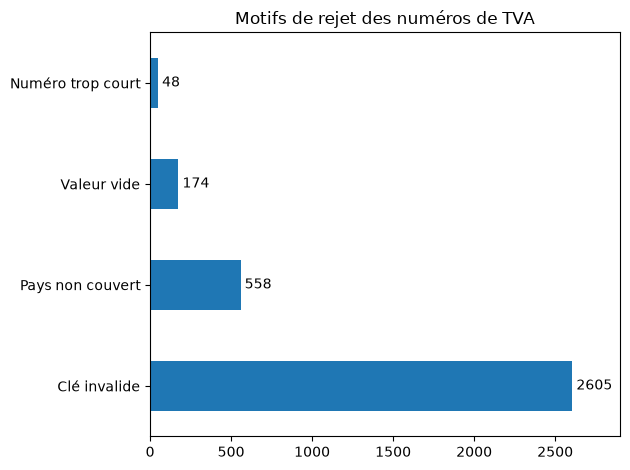

In [130]:

# MOTIFS DE REJET STRUCTUREL

import matplotlib.pyplot as plt

# Sélectionner les numéros rejetés et compter chaque motif
motifs = df.loc[~valides, "resultat_validation"].value_counts()

# Remplacer les noms techniques par des libellés compréhensibles
noms_motifs = {
    (False, "cle_invalide"): "Clé invalide",
    (False, "pays_non_couvert"): "Pays non couvert",
    (False, "vide"): "Valeur vide",
    (False, "trop_court"): "Numéro trop court"
}

motifs = motifs.rename(index=noms_motifs)

# Créer un graphique en barres horizontales
ax = motifs.plot(kind="barh")

# Afficher le nombre de rejets sur chaque barre
ax.bar_label(ax.containers[0], padding=3)

# Améliorer la présentation
ax.set_xlim(0, 2900)
ax.set_ylabel("")
plt.title("Motifs de rejet des numéros de TVA")

# Ajuster les marges et afficher le graphique
plt.tight_layout()
plt.show()



### Analyse du graphique 1

Sur les 3 385 anomalies structurelles identifiées :

- **2 605 (76,96 %)** concernent une clé invalide.
- **558 (16,48 %)** concernent un pays non couvert.
- **174 (5,14 %)** correspondent à des valeurs vides.
- **48 (1,42 %)** concernent des numéros trop courts.

**Conclusion :** les clés invalides représentent la principale cause de rejet structurel.

Ces anomalies nécessitent une vérification ou une correction à partir d'informations fiables. Elles ne signifient pas nécessairement que les entreprises concernées sont inexistantes.

Il est donc recommandé de traiter prioritairement les clés invalides, sans modifier automatiquement les numéros.


In [131]:
df["anomalie"] = ~valides
df.groupby("source_saisie")["anomalie"].mean() * 100

source_saisie
crm                   31.996038
import_fournisseur    33.847737
portail_client        34.070352
reprise_erp           35.152100
saisie_manuelle       34.159919
Name: anomalie, dtype: float64


## Graphique 2 — Taux d'anomalies par canal de saisie

**Objectif :** comparer la proportion de numéros de TVA présentant des anomalies structurelles selon leur canal de saisie.

Les taux sont calculés en pourcentage afin de comparer équitablement les cinq canaux, même si leurs volumes de saisie sont différents.


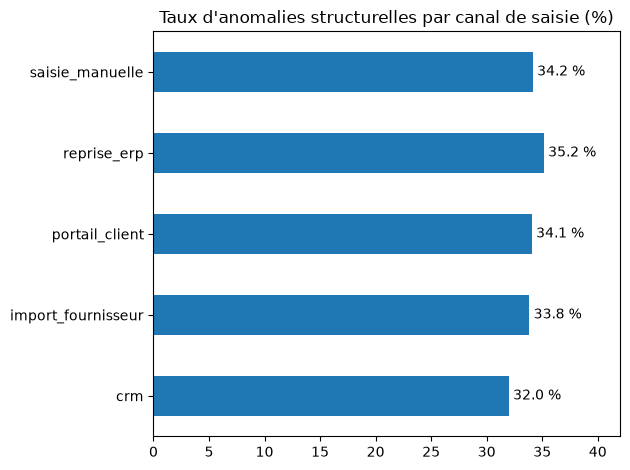

In [132]:
# Calculer le taux d'anomalies par canal de saisie
taux_canaux = df.groupby("source_saisie")["anomalie"].mean() * 100

# Créer un graphique en barres horizontales
ax = taux_canaux.plot(kind="barh")

# Afficher les pourcentages et améliorer la lisibilité
ax.bar_label(ax.containers[0], fmt="%.1f %%", padding=3)
ax.set_xlim(0, 42)
ax.set_ylabel("")

plt.title("Taux d'anomalies structurelles par canal de saisie (%)")
plt.tight_layout()
plt.show()


### Analyse du graphique 2

Les taux d'anomalies structurelles varient selon les canaux :

- **CRM : 32,00 %**
- **Import fournisseur : 33,85 %**
- **Portail client : 34,07 %**
- **Reprise ERP : 35,15 %**
- **Saisie manuelle : 34,16 %**

**Observation :** la reprise ERP présente le taux d'anomalies le plus élevé, tandis que le CRM présente le plus faible.

Cependant, l'écart entre les deux est seulement de **3,15 points de pourcentage**.

**Conclusion :** les anomalies concernent l'ensemble des canaux de saisie. Les différences observées restent relativement faibles et ne permettent pas, à elles seules, d'affirmer qu'un canal est significativement plus problématique.

Une analyse statistique complémentaire serait nécessaire pour confirmer cette hypothèse.



## Graphique 3 — Taux d'anomalies structurelles par pays

**Objectif :** comparer la proportion de numéros de TVA présentant des anomalies selon le pays déclaré dans le CRM.

Nous utilisons des pourcentages plutôt que des nombres bruts afin de tenir compte des différences de volume entre les pays.


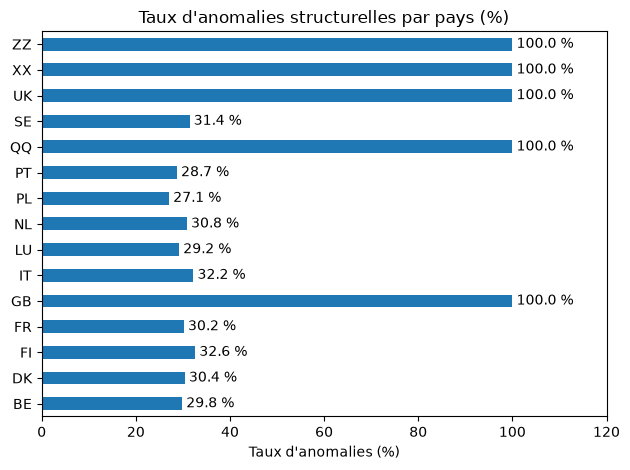

In [133]:
# GRAPHIQUE 3 - ANOMALIES PAR PAYS

taux_pays = df.groupby("pays_declare")["anomalie"].mean() * 100
ax = taux_pays.plot(kind="barh")

ax.bar_label(ax.containers[0], fmt="%.1f %%", padding=3)

plt.title("Taux d'anomalies structurelles par pays (%)")
plt.xlabel("Taux d'anomalies (%)")
plt.ylabel("")
plt.xlim(0, 120)
plt.tight_layout()
plt.show()


### Analyse du graphique 3

Les taux d'anomalies structurelles varient selon le pays déclaré.

Cinq codes pays (`GB`, `UK`, `ZZ`, `XX`, `QQ`) présentent un taux de 100 %. Ils ne sont pas couverts par notre module de validation. Ces résultats reflètent donc principalement une limite de couverture de l'outil, et non nécessairement une mauvaise qualité des données.

Parmi les dix pays couverts, les taux varient de **27,1 % pour la Pologne (PL)** à **32,6 % pour la Finlande (FI)**.

**Conclusion :** il est important de distinguer les anomalies de saisie des limites techniques du module de validation.

Les différences entre pays couverts nécessitent une analyse complémentaire avant de conclure qu'un pays présente davantage d'erreurs.



## Graphique 4 — Évolution mensuelle du taux d'anomalies

**Objectif :** observer l'évolution des anomalies structurelles au fil du temps afin de repérer les périodes présentant davantage de problèmes.

Le taux d'anomalies est calculé pour chaque mois, afin de comparer des périodes ayant des volumes de saisie différents.


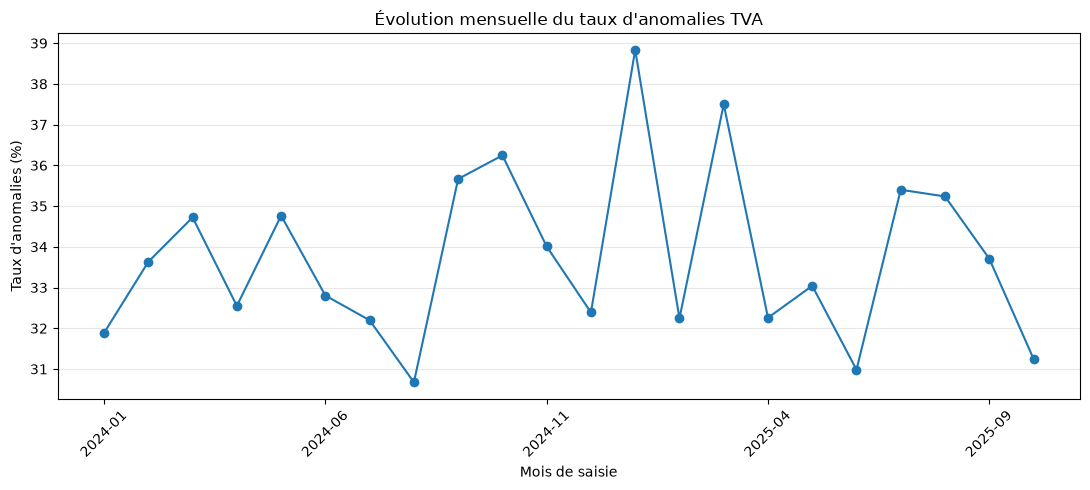

In [134]:
# GRAPHIQUE 4 - EVOLUTION MENSUELLE DES ANOMALIES

df["mois"] = df["date_saisie"].str.slice(0, 7)

# Calculer le taux d'anomalies par mois
taux_mensuel = df.groupby("mois")["anomalie"].mean() * 100

# Trier les mois dans l'ordre chronologique
taux_mensuel = taux_mensuel.sort_index()

# Créer un graphique en courbe
ax = taux_mensuel.plot(kind="line", marker="o", figsize=(11, 5))

# Personnaliser le graphique
plt.title("Évolution mensuelle du taux d'anomalies TVA")
plt.xlabel("Mois de saisie")
plt.ylabel("Taux d'anomalies (%)")
plt.grid(axis="y", alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



### Analyse du graphique 4

Le taux d'anomalies structurelles évolue en dents de scie entre janvier 2024 et octobre 2025, avec des valeurs comprises approximativement entre 31 % et 39 %.

On observe des variations mensuelles, mais aucune tendance nette à la hausse ou à la baisse.

**Conclusion :** la qualité des données ne montre ni amélioration régulière ni dégradation progressive sur la période étudiée.

Ces fluctuations doivent être interprétées avec prudence, notamment pour octobre 2025, qui ne compte que 16 saisies.

Un suivi mensuel permettrait de vérifier si cette situation se maintient dans le temps.
